# Итоговый мини-проект
## Обучаемое сжатие изображений

Выполнили: Сальников Никита 932301, Корепанов Дмитрий 932302

## Цель работы

Разработать и исследовать обучаемый нейросетевой кодек для эффективного сжатия изображений с сохранением высокого визуального качества.

## Задачи

1. Изучить современные методы обучаемого сжатия изображений.
2. Разработать и обучить нейросетевой кодек.
3. Сравнить с традиционными и современными кодеками (Например, JPEG).

Как задачи отражены в тетради: задача 1 - разделы "Основные понятия" и "Изученные методы"; задача 2 - разделы о наборах данных, их подготовке и "Обучение собственного кодека"; задача 3 - разделы "Оценка на Kodak" и "Сравнение кодеков".

## Настройка

Тетрадь лежит в `src/experiments/`. Все пути строятся от корня проекта. Тяжелые шаги, которые требуют других окружений, выполнены заранее скриптами и здесь только читаются:

- обучение кодека - `src/scripts/train_hyperprior_kaggle.py` на Kaggle (2x Tesla T4);
- JPEG и WebP - `src/scripts/run_baselines.py`;
- PULSE - `src/scripts/run_pulse.py` (официальный код Microsoft GenCodec, отдельное окружение);
- DiT-IC - `src/scripts/run_dit_ic.py`.

Оценка собственного кодека на Kodak выполняется прямо в тетради.

In [1]:
# Общие импорты, пути и параметры отображения
import os
import sys
import json
import time
import platform
from pathlib import Path

# Корень проекта: тетрадь лежит в src/experiments/
PROJECT_ROOT = Path.cwd().resolve().parents[1]
SRC_ROOT = PROJECT_ROOT / "src"
CACHE_ROOT = SRC_ROOT / "models" / "cache"
# Веса метрик (LPIPS, DISTS, CLIP-IQA, MUSIQ) кешируются внутри проекта
os.environ.setdefault("TORCH_HOME", str(CACHE_ROOT / "torch"))
os.environ.setdefault("XDG_CACHE_HOME", str(CACHE_ROOT))
sys.dont_write_bytecode = True

# Скрываем служебные предупреждения библиотек, которые не влияют на результаты
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*IProgress not found.*")

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

KODAK_DIR = SRC_ROOT / "images" / "kodak"              # тестовый набор
METRICS_DIR = SRC_ROOT / "result" / "metrics"           # CSV с результатами
KAGGLE_DIR = SRC_ROOT / "result" / "hyperprior" / "kaggle"  # веса и журналы обучения с Kaggle
PULSE_DIR = SRC_ROOT / "result" / "pulse"              # реконструкции PULSE
FIGURES_DIR = SRC_ROOT / "result" / "figures" / "project"   # рисунки для презентации
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

# Крупные шрифты, чтобы рисунки читались на слайдах
plt.rcParams.update({"font.size": 13, "axes.titlesize": 14, "axes.labelsize": 13,
                     "legend.fontsize": 10, "figure.dpi": 110})
pd.set_option("display.precision", 4)

In [2]:
# Версии библиотек и оборудование - для воспроизводимости
import compressai
import pyiqa
import torchmetrics

print("Python     :", platform.python_version())
print("ОС         :", platform.platform())
print("PyTorch    :", torch.__version__, "| CUDA:", torch.version.cuda)
print("CompressAI :", compressai.__version__)
print("pyiqa      :", pyiqa.__version__, "| torchmetrics:", torchmetrics.__version__)
print("GPU        :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "нет")

Python     : 3.12.3
ОС         : Linux-6.18.58.1-microsoft-standard-WSL2-x86_64-with-glibc2.39
PyTorch    : 2.5.0+cu124 | CUDA: 12.4
CompressAI : 1.2.8
pyiqa      : 0.1.14.1 | torchmetrics: 1.8.2
GPU        : NVIDIA GeForce RTX 4070 Laptop GPU


**Результат:** оценка выполнена в WSL2 (Python 3.12.3, PyTorch 2.5.0 с CUDA 12.4, CompressAI 1.2.8, pyiqa 0.1.14.1, torchmetrics 1.8.2) на NVIDIA GeForce RTX 4070 Laptop GPU. Обучение шло на Kaggle: PyTorch 2.11.0, две Tesla T4. При повторном запуске метрики могут отличаться в последних знаках из-за недетерминизма вычислений на GPU (cuDNN).

## Основные понятия

Термины, которые встречаются дальше, простыми словами.

| Понятие | Что это |
|---|---|
| Кодек | программа из двух частей: кодер превращает изображение в файл (поток бит), декодер восстанавливает изображение из файла |
| Битрейт, bpp | бит на пиксель: размер файла в битах, деленный на число пикселей. Несжатое цветное изображение - 24 bpp, PNG без потерь - около 13 bpp, рабочие точки в этой работе - 0,1-0,6 bpp |
| Сжатие с потерями | восстановленное изображение немного отличается от исходного; чем меньше bpp, тем больше отличий |
| Латентное представление (латент) y | набор чисел, в который нейросеть-кодер переводит изображение. Для фото 768x512 это 192 карты 32x48 - в 4 раза меньше чисел, чем в исходном изображении (3 канала цвета) |
| Квантование | округление латента до целых: в файл можно записать только целые числа. Здесь и возникают потери |
| Энтропийное (арифметическое) кодирование | запись целых чисел в биты без потерь: частые значения получают короткие коды, редкие - длинные. Чем точнее известна вероятность каждого значения, тем меньше файл |
| Гиперприор, гиперлатент z | маленькая "подсказка", которую кодер записывает в файл первой: насколько сильно разбросаны числа латента в каждой области (масштаб). По подсказке арифметический кодер точнее знает вероятности и тратит меньше бит |
| Scale hyperprior | название архитектуры (Balle и др., 2018), дословно "гиперприор масштаба": кодек с такой подсказкой о масштабе. Это наш собственный кодек |
| lambda | число в функции потерь, которое задает уровень качества при обучении: больше lambda - выше качество и больше файл. Для каждого lambda обучается своя модель |
| QP | уровень качества у PULSE: одна модель работает на 8 уровнях, QP 0 - самое сильное сжатие |
| На точность (MSE) и на восприятие (perceptual) | чему обучен кодек: повторять пиксели как можно точнее или выглядеть для человека как оригинал, даже если пиксели немного другие |

## Описание наборов данных

Используются два набора, они не пересекаются: DIV2K только для обучения, Kodak только для проверки.

### DIV2K - обучающий набор

**Откуда:** DIV2K (DIVerse 2K resolution images), Agustsson и Timofte, 2017; собран для соревнований NTIRE 2017 и 2018 по повышению разрешения изображений (ETH Zurich). Копия на Kaggle: `soumikrakshit/div2k-high-resolution-images`.

**Описание авторов (перевод):** "Большой новый набор цветных (RGB) изображений с большим разнообразием содержания. Набор делится на обучающую часть (800 изображений высокой четкости и высокого разрешения), валидационную (100 изображений) и тестовую (100 изображений)." На снимках люди, животные, природа, города, предметы и текстуры.

**Одна запись:** цветная фотография PNG (RGB, 8 бит на канал) около 2040 пикселей по длинной стороне. Меток нет: для кодека правильный ответ - само изображение, сеть учится его восстанавливать.

**Что с ним делаем:** из 800 обучающих изображений вырезаются случайные фрагменты 256x256, на них обучается кодек. Валидационная и тестовая части DIV2K не используются.

**Зачем:** много разнообразных четких деталей - сеть видит текстуры, края и гладкие области, которые встречаются в любых фотографиях.

### Kodak - тестовый набор

**Откуда:** Kodak Lossless True Color Image Suite - 24 фотографии, которые компания Eastman Kodak выпустила для свободного использования (отсканированные кадры фотопленки; страница r0k.us/graphics/kodak).

**Одна запись:** цветная фотография PNG 768x512 (или 512x768), RGB, 8 бит на канал, сохранена без потерь. На снимках люди, дома, лодки, природа, попугаи.

**Что измеряем:** насколько маленьким получается файл (bpp) и насколько восстановленное изображение похоже на исходное (метрики качества).

**Зачем:** Kodak - стандартный тест в статьях о сжатии изображений, поэтому наши числа можно сравнить с опубликованными.

Обучение и проверка на разных наборах исключают утечку: модель ни разу не видела тестовые изображения.

In [3]:
# Пути к наборам. DIV2K хранится локально только для анализа (обучение шло на Kaggle)
DIV2K_DIR = SRC_ROOT / "images" / "div2k" / "DIV2K_train_HR"
div2k_paths = sorted(DIV2K_DIR.glob("*.png"))
kodak_paths = sorted(KODAK_DIR.glob("*.png"))
if not div2k_paths:
    raise FileNotFoundError(f"Нет DIV2K в {DIV2K_DIR}: скачайте набор soumikrakshit/div2k-high-resolution-images "
                            "с Kaggle и распакуйте сюда папку DIV2K_train_HR")
print("DIV2K (обучение):", len(div2k_paths), "файлов | Kodak (проверка):", len(kodak_paths), "файлов")

DIV2K (обучение): 800 файлов | Kodak (проверка): 24 файлов


## Анализ данных

### Количество, размеры и формат

In [4]:
# Размер, режим и размер PNG без потерь для каждого изображения; файлы, которые не открываются, считаются отдельно
import hashlib


def describe_images(paths, dataset):
    """Таблица по изображениям: размеры, режим, bpp файла PNG и контрольная сумма MD5 для поиска дубликатов."""
    rows, broken = [], []
    for path in paths:
        try:
            with Image.open(path) as image:
                image.verify()  # проверка целостности файла
            with Image.open(path) as image:
                image.load()  # полное декодирование: поврежденные данные дадут ошибку здесь
                width, height, mode = image.size[0], image.size[1], image.mode
        except Exception as error:
            broken.append((path.name, str(error)))
            continue
        data = path.read_bytes()
        rows.append({"Набор": dataset, "Файл": path.name, "Ширина": width, "Высота": height, "Режим": mode,
                     "PNG, bpp": len(data) * 8 / (width * height), "MD5": hashlib.md5(data).hexdigest()})
    return pd.DataFrame(rows), broken


div2k_info, div2k_broken = describe_images(div2k_paths, "DIV2K")
kodak_info, kodak_broken = describe_images(kodak_paths, "Kodak")
images_info = pd.concat([div2k_info, kodak_info], ignore_index=True)
images_info["Пикселей, млн"] = images_info["Ширина"] * images_info["Высота"] / 1e6

dataset_table = images_info.groupby("Набор", sort=False).agg(
    images=("Файл", "size"), modes=("Режим", lambda m: ", ".join(sorted(set(m)))),
    w_min=("Ширина", "min"), w_max=("Ширина", "max"), h_min=("Высота", "min"), h_max=("Высота", "max"),
    mpix=("Пикселей, млн", "mean"), png_bpp=("PNG, bpp", "mean"),
)
dataset_table.columns = ["Изображений", "Режим", "Ширина, мин", "Ширина, макс", "Высота, мин", "Высота, макс",
                         "Пикселей, млн (среднее)", "PNG, bpp (среднее)"]
dataset_table["Поврежденных файлов"] = [len(div2k_broken), len(kodak_broken)]
dataset_table.to_csv(METRICS_DIR / "project-datasets.csv")
display(dataset_table)

landscape = int((kodak_info["Ширина"] > kodak_info["Высота"]).sum())
print(f"Kodak: {landscape} альбомных и {len(kodak_info) - landscape} книжных изображений")
print(f"DIV2K: длинная сторона от {div2k_info[['Ширина', 'Высота']].max(axis=1).min()} "
      f"до {div2k_info[['Ширина', 'Высота']].max(axis=1).max()} пикселей")

,Изображений,Режим,"Ширина, мин","Ширина, макс","Высота, мин","Высота, макс","Пикселей, млн (среднее)","PNG, bpp (среднее)",Поврежденных файлов
Набор,,,,,,,,,
DIV2K,800,RGB,1116,2040,648,2040,2.7880,12.6869,0
Kodak,24,RGB,512,768,512,768,0.3932,13.0499,0


Kodak: 18 альбомных и 6 книжных изображений
DIV2K: длинная сторона от 2040 до 2040 пикселей


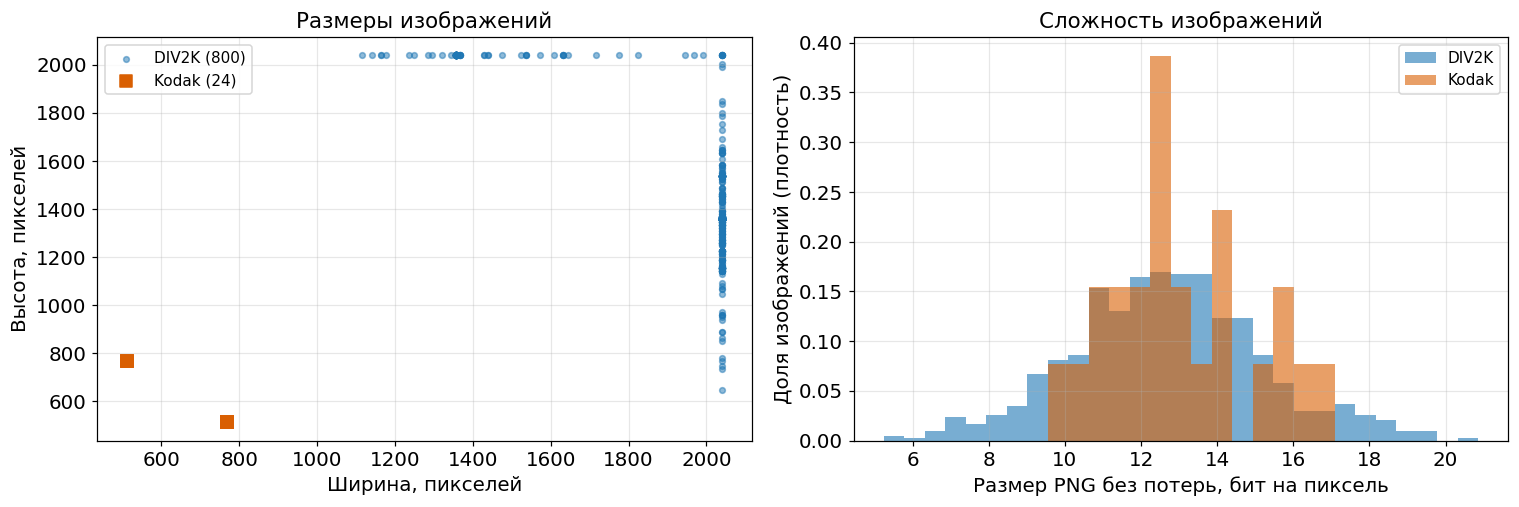

In [5]:
# Размеры изображений и их "сложность": сколько бит на пиксель нужно PNG без потерь
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].scatter(div2k_info["Ширина"], div2k_info["Высота"], s=14, alpha=0.5, label="DIV2K (800)")
axes[0].scatter(kodak_info["Ширина"], kodak_info["Высота"], s=60, marker="s", color="#d95f02", label="Kodak (24)")
axes[0].set_xlabel("Ширина, пикселей")
axes[0].set_ylabel("Высота, пикселей")
axes[0].set_title("Размеры изображений")
axes[0].legend()
axes[0].grid(alpha=0.3)
bins = np.linspace(images_info["PNG, bpp"].min(), images_info["PNG, bpp"].max(), 30)
axes[1].hist(div2k_info["PNG, bpp"], bins=bins, density=True, alpha=0.6, label="DIV2K")
axes[1].hist(kodak_info["PNG, bpp"], bins=bins, density=True, alpha=0.6, color="#d95f02", label="Kodak")
axes[1].set_xlabel("Размер PNG без потерь, бит на пиксель")
axes[1].set_ylabel("Доля изображений (плотность)")
axes[1].set_title("Сложность изображений")
axes[1].legend()
axes[1].grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "datasets-sizes.png", dpi=150, bbox_inches="tight")
plt.show()

**Результат:** DIV2K в 7 раз крупнее Kodak по числу пикселей (2,79 против 0,39 млн), длинная сторона всегда 2040. По сложности наборы близки: PNG без потерь - 12,69 и 13,05 бит на пиксель, у DIV2K разброс шире (примерно от 5 до 21) - в обучении есть и очень простые, и очень сложные снимки. Kodak: 24 изображения, 18 альбомных 768x512 и 6 книжных 512x768; без потерь они занимают в среднем 13,05 бит на пиксель, поэтому 0,2 bpp - это сжатие примерно в 65 раз относительно PNG и в 120 раз относительно несжатых 24 бит на пиксель.

### Поврежденные файлы и дубликаты

Точные дубликаты ищутся по контрольной сумме MD5 файла. Почти одинаковые снимки (тот же кадр после пересохранения или уменьшения) - по корреляции уменьшенных копий 32x32 в оттенках серого: у одинаковых изображений она близка к 1. Отдельно проверяется, нет ли тестовых изображений Kodak в обучающем наборе.

In [6]:
# Уменьшенные копии 32x32 в оттенках серого, нормированные: скалярное произведение двух копий - их корреляция
def thumbnail_vector(path):
    with Image.open(path) as image:
        small = np.asarray(image.convert("L").resize((32, 32), Image.Resampling.BILINEAR), dtype=np.float64).ravel()
    small -= small.mean()
    return small / (np.linalg.norm(small) + 1e-12)


div2k_thumbs = np.stack([thumbnail_vector(p) for p in div2k_paths])
kodak_thumbs = np.stack([thumbnail_vector(p) for p in kodak_paths])

# Все пары внутри DIV2K (изображение само с собой исключено) и все пары Kodak - DIV2K
within = div2k_thumbs @ div2k_thumbs.T
np.fill_diagonal(within, -1)
i, j = np.unravel_index(within.argmax(), within.shape)
cross = kodak_thumbs @ div2k_thumbs.T
k, d = np.unravel_index(cross.argmax(), cross.shape)

checks = pd.DataFrame([
    {"Проверка": "поврежденные файлы", "Результат": f"DIV2K: {len(div2k_broken)}, Kodak: {len(kodak_broken)}"},
    {"Проверка": "точные дубликаты внутри DIV2K (MD5)", "Результат": str(int(div2k_info["MD5"].duplicated().sum()))},
    {"Проверка": "одинаковые файлы в DIV2K и Kodak (MD5)",
     "Результат": str(len(set(div2k_info["MD5"]) & set(kodak_info["MD5"])))},
    {"Проверка": "самая похожая пара внутри DIV2K",
     "Результат": f"{div2k_paths[i].stem} и {div2k_paths[j].stem}, корреляция {within[i, j]:.4f}"},
    {"Проверка": "самая похожая пара Kodak - DIV2K",
     "Результат": f"{kodak_paths[k].stem} и {div2k_paths[d].stem}, корреляция {cross[k, d]:.4f}"},
])
checks.to_csv(METRICS_DIR / "project-data-checks.csv", index=False)
display(checks)

,Проверка,Результат
0,поврежденные файлы,"DIV2K: 0, Kodak: 0"
1,точные дубликаты внутри DIV2K (MD5),0
2,одинаковые файлы в DIV2K и Kodak (MD5),0
3,самая похожая пара внутри DIV2K,"0059 и 0637, корреляция 0.8889"
4,самая похожая пара Kodak - DIV2K,"kodim06 и 0637, корреляция 0.8333"


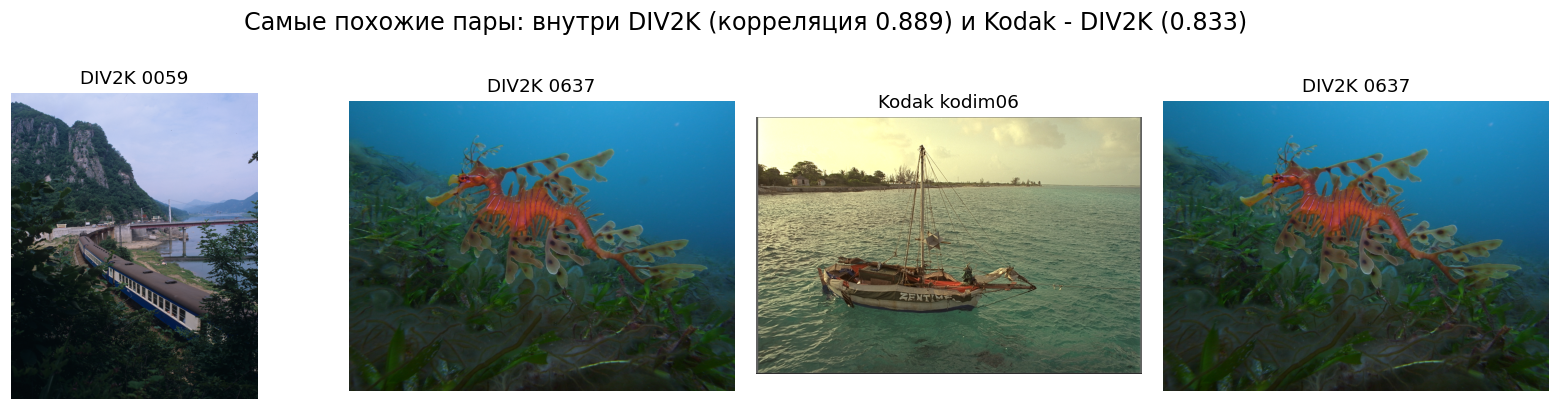

In [7]:
# Самые похожие пары рядом: видно, один ли это кадр
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
pairs = [(div2k_paths[i], "DIV2K"), (div2k_paths[j], "DIV2K"), (kodak_paths[k], "Kodak"), (div2k_paths[d], "DIV2K")]
for axis, (path, name) in zip(axes, pairs):
    axis.imshow(Image.open(path))
    axis.set_title(f"{name} {path.stem}", fontsize=12)
    axis.axis("off")
fig.suptitle(f"Самые похожие пары: внутри DIV2K (корреляция {within[i, j]:.3f}) и Kodak - DIV2K ({cross[k, d]:.3f})")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "datasets-similar.png", dpi=120, bbox_inches="tight")
plt.show()

**Результат:** Поврежденных файлов и точных дубликатов нет, изображений Kodak в DIV2K нет. Самые похожие пары (корреляция 0,889 и 0,833) - разные сцены, похожа только раскладка яркости: утечки нет.

### Примеры изображений

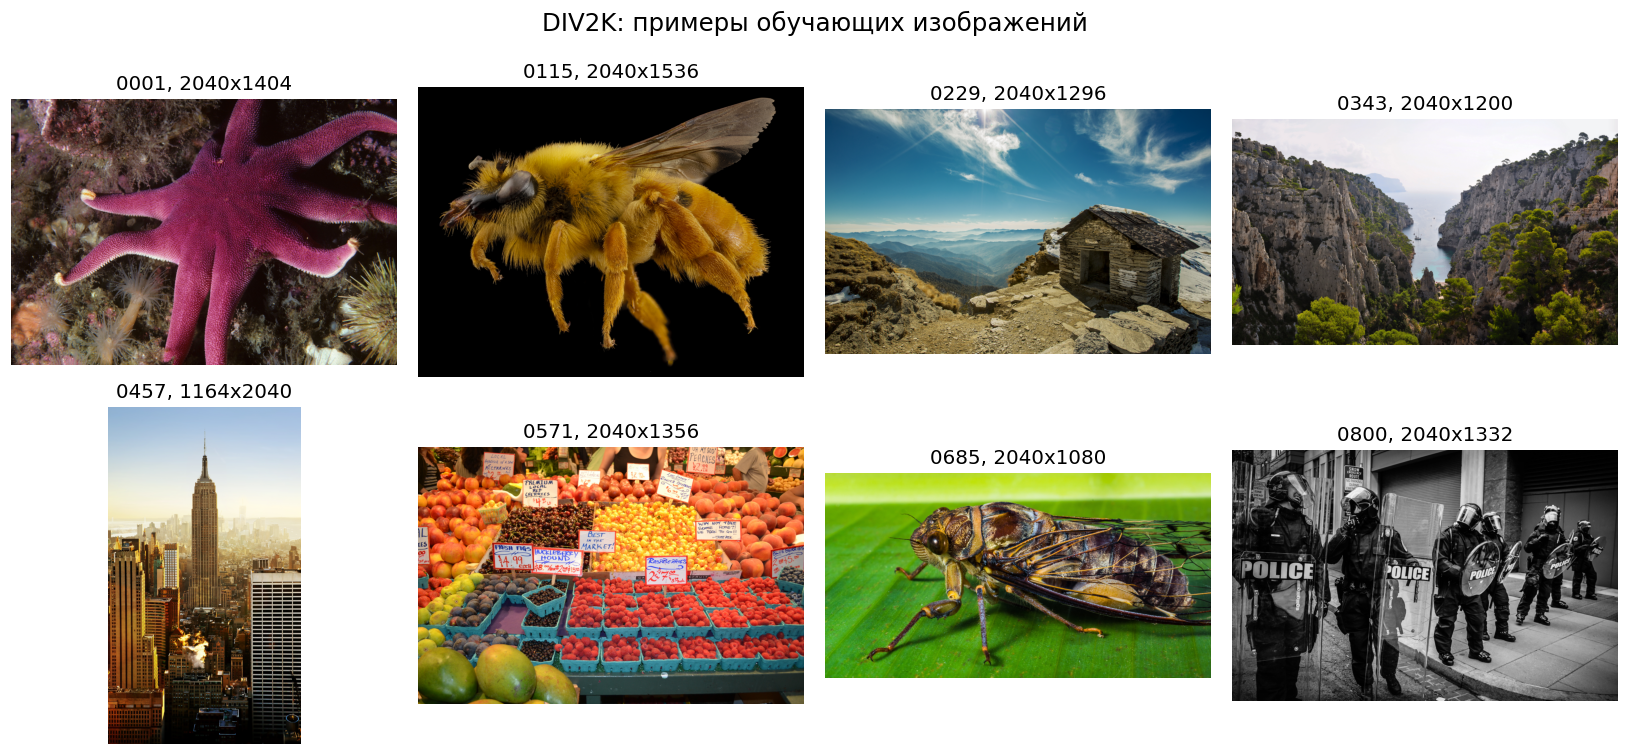

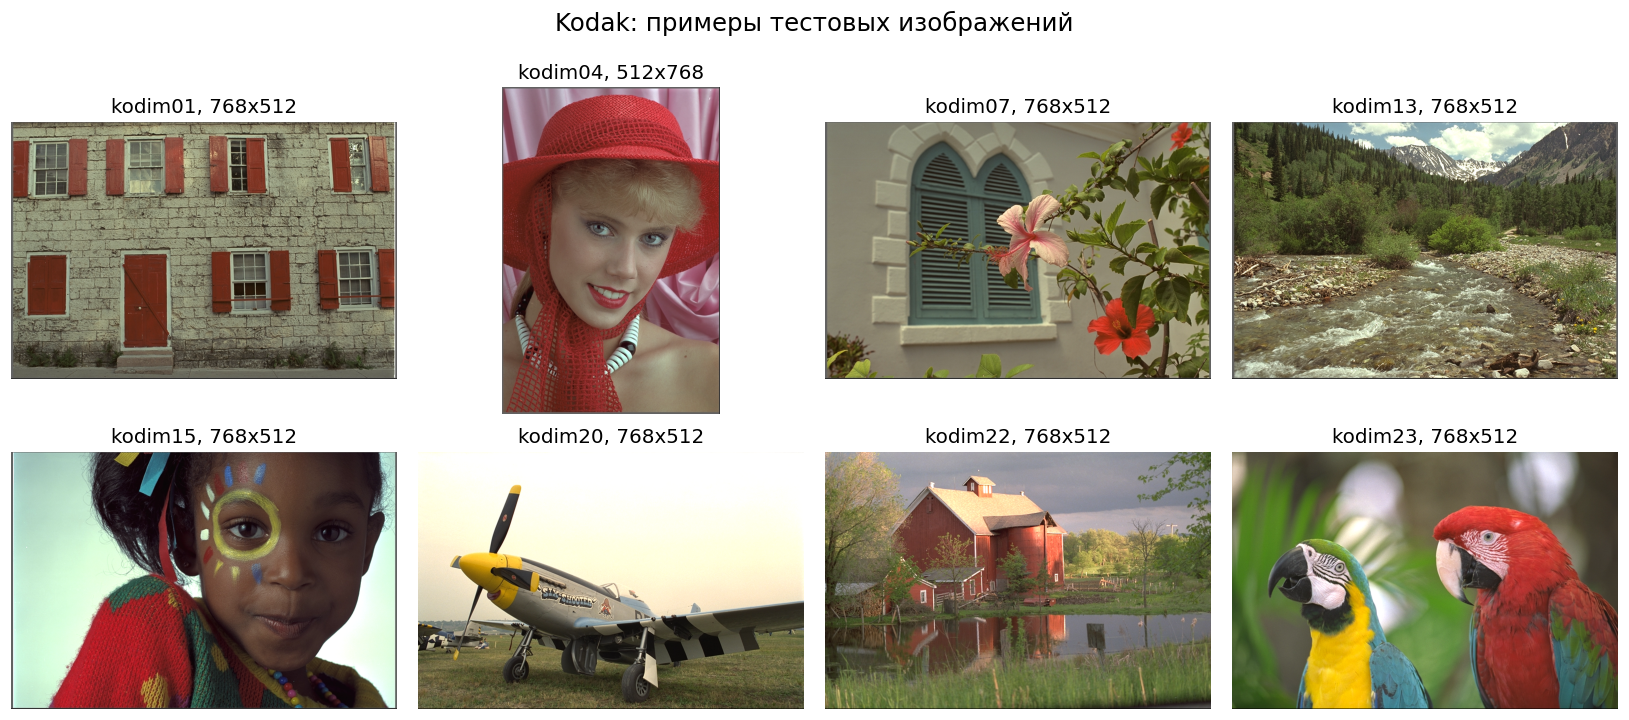

In [8]:
# По 8 примеров из каждого набора; из DIV2K - равномерно по списку файлов
def show_examples(paths, title, file_name):
    fig, axes = plt.subplots(2, 4, figsize=(15, 7))
    for axis, path in zip(axes.ravel(), paths):
        with Image.open(path) as image:
            axis.imshow(image)
            axis.set_title(f"{path.stem}, {image.size[0]}x{image.size[1]}", fontsize=13)
        axis.axis("off")
    fig.suptitle(title, fontsize=16)
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / file_name, dpi=110, bbox_inches="tight")
    plt.show()


show_examples([div2k_paths[n] for n in np.linspace(0, len(div2k_paths) - 1, 8).astype(int)],
              "DIV2K: примеры обучающих изображений", "div2k-examples.png")
show_examples([kodak_paths[n] for n in (0, 3, 6, 12, 14, 19, 21, 22)],
              "Kodak: примеры тестовых изображений", "kodak-examples.png")

**Результат:** DIV2K: разнообразные сюжеты: макро, пейзажи, город, люди, еда; есть вертикальные и черно-белые снимки. Kodak: обычные фотографии с гладкими областями (небо, кожа) и мелкими деталями (перья, листва) - на них видно, где кодек размывает.

## Подготовка данных

| Выборка | Набор | Изображений | Что подается в сеть |
|---|---|---|---|
| обучающая | DIV2K train | 800 | случайные фрагменты 256x256: половина из исходных изображений, половина из уменьшенных вдвое копий (фильтр Lanczos); случайное отражение по горизонтали |
| валидационная | - | - | не используется: lambda, шаг обучения и размер сети взяты из статьи и CompressAI, выбирать между вариантами не нужно; берутся веса в конце обучения |
| тестовая | Kodak | 24 | изображение целиком; дополняется повтором краевых пикселей до размера, кратного 64 (сеть уменьшает размер в 64 раза), после декодирования лишнее обрезается |

Пиксели переводятся из 0-255 в диапазон [0, 1] делением на 255. Уменьшенные вдвое копии нужны, чтобы фрагмент 256x256 иногда охватывал объект целиком, а не только мелкую текстуру: так обучающие фрагменты ближе к изображениям Kodak, которые по стороне в 2,7 раза меньше DIV2K.

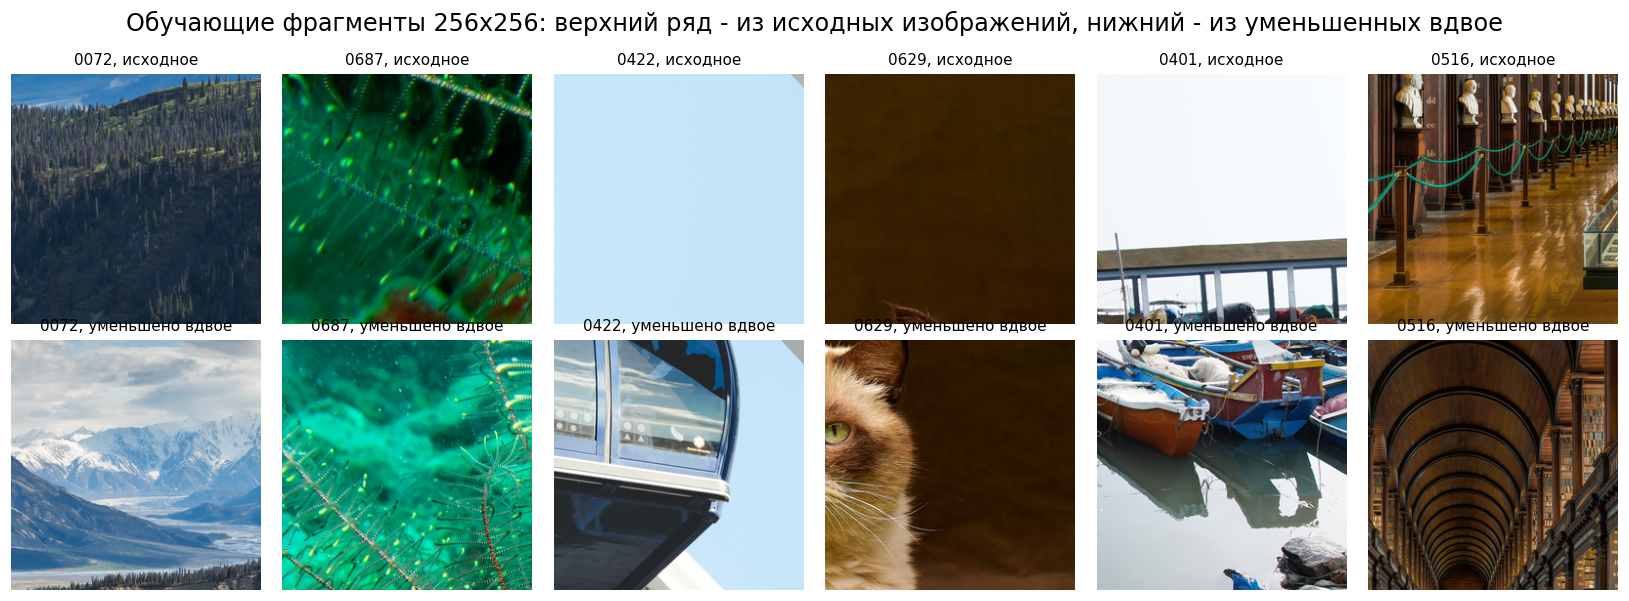

In [9]:
# Как выглядят обучающие фрагменты: случайные 256x256 из исходного и из уменьшенного вдвое изображения
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(2, 6, figsize=(15, 5.6))
for column in range(6):
    path = div2k_paths[rng.integers(len(div2k_paths))]
    with Image.open(path) as image:
        image = image.convert("RGB")
        half = image.resize((image.size[0] // 2, image.size[1] // 2), Image.Resampling.LANCZOS)
    for row, (source, name) in enumerate(((image, "исходное"), (half, "уменьшено вдвое"))):
        left, top = rng.integers(source.size[0] - 256), rng.integers(source.size[1] - 256)
        axes[row, column].imshow(source.crop((left, top, left + 256, top + 256)))
        axes[row, column].set_title(f"{path.stem}, {name}", fontsize=10)
        axes[row, column].axis("off")
fig.suptitle("Обучающие фрагменты 256x256: верхний ряд - из исходных изображений, нижний - из уменьшенных вдвое")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "train-crops.png", dpi=110, bbox_inches="tight")
plt.show()

**Результат:** Фрагмент из исходного 2K-снимка часто почти однотонный (небо, стена), из уменьшенной копии - чаще содержит объект целиком; так обучение ближе к масштабу изображений Kodak.

## Изученные методы

Сравниваются кодеки трех типов. Для всех битрейт - это реальный размер сжатого файла.

| Кодек | Тип | Как работает (простыми словами) | Весов |
|---|---|---|---|
| JPEG (1992) | классический | делит изображение на блоки 8x8, раскладывает каждый блок на "волны" разной частоты (DCT) и грубо округляет мелкие детали | нет: алгоритм написан вручную |
| WebP (2010) | классический | предсказывает блок по уже переданным соседям и кодирует только ошибку предсказания | нет |
| Наш кодек: scale hyperprior (Balle и др., 2018) | обучаемый, на точность | нейросеть-кодер переводит изображение в латент, подсказка о масштабе (гиперприор) помогает записать его коротко, нейросеть-декодер восстанавливает изображение; обучен нами с нуля | 5,1 млн |
| CompressAI (эталон) | обучаемый, на точность | та же сеть, но официальные веса библиотеки CompressAI - для проверки нашего обучения | 5,1 млн |
| PULSE (Microsoft, 2026) | обучаемый | современный быстрый кодек, одна модель на 8 уровней качества (QP 0-7); две модели обучены на точность (PULSE-S - маленькая, PULSE), две - на восприятие (PULSE, PULSE-L - большая) | 12,7-19,3 млн |
| DiT-IC (CVPR 2026) | генеративный | передает очень сжатый латент, а диффузионная нейросеть за один шаг дорисовывает по нему правдоподобное изображение | 1 069 млн |

**Почему собственный кодек - scale hyperprior.** Это базовая архитектура, на которой построены почти все современные обучаемые кодеки (в том числе PULSE); каждый ее блок можно объяснить; у CompressAI есть официальные веса этой же сети, поэтому качество нашего обучения можно проверить.

**DiT-IC в сравнении - одна точка.** Измерен один уровень качества, q3 (0,08 bpp). Даже самый высокий уровень DiT-IC, q4, дает около 0,1 bpp, поэтому в сравнениях при 0,2 и 0,4 bpp его нет: он рассчитан только на очень сильное сжатие.

**Метрики качества** считаются одним и тем же кодом для всех кодеков (`src/scripts/metrics_utils.py`):

| Метрика | Что сравнивает (простыми словами) | Как читать (ориентир) |
|---|---|---|
| PSNR, дБ | насколько точно совпадают пиксели: средняя ошибка в логарифмической шкале | больше - лучше; около 30 дБ и выше мелкие отличия почти не видны; +1 дБ - заметное улучшение |
| MS-SSIM | совпадают ли яркость, контраст и структура на нескольких масштабах | от 0 до 1, больше - лучше; выше 0,95 - очень похоже |
| LPIPS | насколько различаются изображения "глазами" нейросети AlexNet; ее оценку настроили по ответам людей | 0 - одинаковые, меньше - лучше; около 0,1 и ниже отличия почти не заметны |
| DISTS | то же для структуры и текстуры (нейросеть VGG): отличает размытие от правдоподобной текстуры | меньше - лучше |
| CLIP-IQA, MUSIQ | насколько изображение само по себе выглядит качественным, без сравнения с оригиналом | больше - лучше; дополнительные |

Почему нужны обе группы: кодек на точность выигрывает по PSNR, но размывает детали; кодек на восприятие дорисовывает текстуру - пиксели другие, а для глаза ближе к оригиналу. Это видно только по LPIPS и DISTS.

## Обучение собственного кодека

### Архитектура

Кодек состоит из четырех сверточных нейросетей и энтропийного кодера (схема ниже):

- `g_a`, кодер: изображение 3 x H x W -> латент y размера 192 x H/16 x W/16; 4 свертки с шагом 2, каждая уменьшает карту вдвое;
- `h_a`, кодер подсказки: |y| -> гиперлатент z размера 128 x H/64 x W/64 - подсказка о масштабе, она записывается в файл первой;
- `h_s`, декодер подсказки: z -> масштаб sigma для каждого числа латента; по нему арифметический кодер знает, какие значения вероятны;
- `g_s`, декодер: округленный латент -> восстановленное изображение; 4 транспонированные свертки, каждая увеличивает карту вдвое.

Вместо ReLU в `g_a` и `g_s` стоит GDN (generalized divisive normalization): каждое значение делится на величину, зависящую от соседних каналов. Так каналы становятся менее зависимыми, и латент записывается короче.

In [10]:
# Модель той же конфигурации, что обучалась на Kaggle: N=128 каналов внутри, M=192 канала латента
from compressai.models import ScaleHyperprior

model_demo = ScaleHyperprior(N=128, M=192).eval()

# Послойная сводка (аналог model.summary): выход каждого слоя для изображения Kodak 768x512
layer_rows, hooks = [], []
for block_name, block in (("g_a", model_demo.g_a), ("h_a", model_demo.h_a), ("h_s", model_demo.h_s),
                          ("g_s", model_demo.g_s)):
    for layer_name, layer in block.named_children():
        def record(module, inputs, output, block_name=block_name, layer_name=layer_name):
            layer_rows.append({"Блок": block_name, "Слой": f"{layer_name}: {module.__class__.__name__}",
                               "Выход (каналы x высота x ширина)": " x ".join(str(s) for s in output.shape[1:]),
                               "Параметров": sum(p.numel() for p in module.parameters())})
        hooks.append(layer.register_forward_hook(record))
with torch.no_grad():
    x_demo = torch.rand(1, 3, 512, 768)
    y_demo = model_demo.g_a(x_demo)
    z_demo = model_demo.h_a(torch.abs(y_demo))
    sigma_demo = model_demo.h_s(z_demo)
    x_hat_demo = model_demo.g_s(y_demo)
for hook in hooks:
    hook.remove()
pd.set_option("display.max_rows", 40)
display(pd.DataFrame(layer_rows))

,Блок,Слой,Выход (каналы x высота x ширина),Параметров
0,g_a,0: Conv2d,128 x 256 x 384,9728
1,g_a,1: GDN,128 x 256 x 384,16512
2,g_a,2: Conv2d,128 x 128 x 192,409728
3,g_a,3: GDN,128 x 128 x 192,16512
4,g_a,4: Conv2d,128 x 64 x 96,409728
5,g_a,5: GDN,128 x 64 x 96,16512
6,g_a,6: Conv2d,192 x 32 x 48,614592
7,h_a,0: Conv2d,128 x 32 x 48,221312
8,h_a,1: ReLU,128 x 32 x 48,0
9,h_a,2: Conv2d,128 x 16 x 24,409728


In [11]:
# Число весов по блокам
blocks = {"g_a (кодер)": model_demo.g_a, "h_a (кодер подсказки)": model_demo.h_a,
          "h_s (декодер подсказки)": model_demo.h_s, "g_s (декодер)": model_demo.g_s,
          "энтропийная модель z": model_demo.entropy_bottleneck}
architecture = pd.DataFrame(
    [{"Блок": name, "Параметров": sum(p.numel() for p in block.parameters())} for name, block in blocks.items()]
)
architecture.loc[len(architecture)] = {"Блок": "Всего", "Параметров": sum(p.numel() for p in model_demo.parameters())}
display(architecture)
print("x:", tuple(x_demo.shape), "-> y:", tuple(y_demo.shape), "-> z:", tuple(z_demo.shape),
      "-> sigma:", tuple(sigma_demo.shape), "-> x_hat:", tuple(x_hat_demo.shape))

,Блок,Параметров
0,g_a (кодер),1493312
1,h_a (кодер подсказки),1040768
2,h_s (декодер подсказки),1040832
3,g_s (декодер),1493123
4,энтропийная модель z,7808
5,Всего,5075843


x: (1, 3, 512, 768) -> y: (1, 192, 32, 48) -> z: (1, 128, 8, 12) -> sigma: (1, 192, 32, 48) -> x_hat: (1, 3, 512, 768)


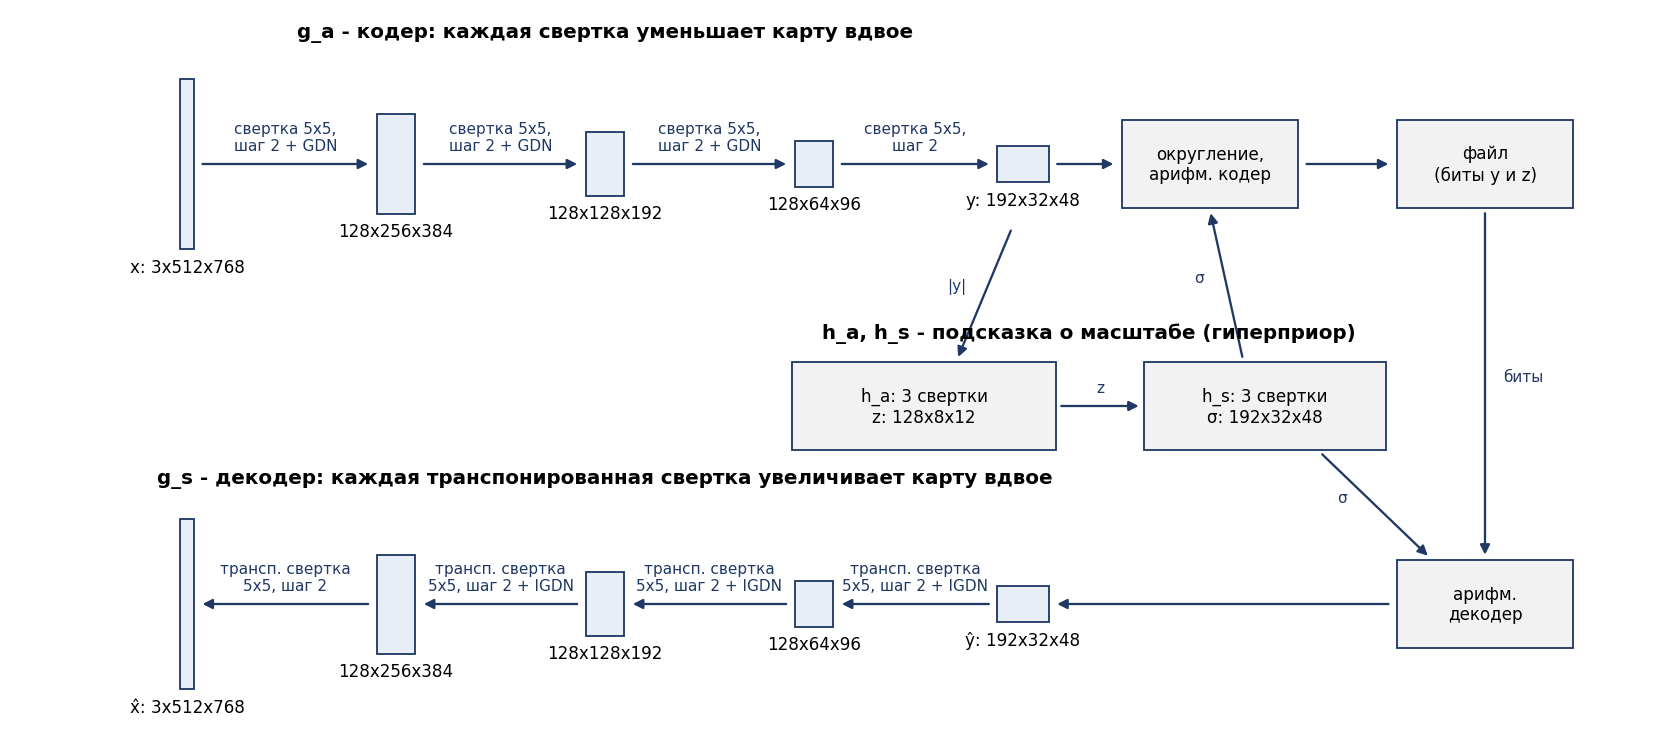

In [12]:
# Схема архитектуры для изображения 768x512: высота прямоугольника - сторона карты, ширина - число каналов
from matplotlib.patches import Rectangle

BLUE, FILL = "#1F3864", "#E8EEF7"
fig = plt.figure(figsize=(15, 6.6))
ax = fig.add_axes([0, 0, 1, 1])
ax.set_xlim(0, 15)
ax.set_ylim(0, 6.6)
ax.axis("off")


def tensor(x, y, channels, side, label):
    """Тензор: возвращает половину ширины прямоугольника."""
    height, width = 0.25 + 1.3 * side / 512, 0.12 + 0.0018 * channels
    ax.add_patch(Rectangle((x - width / 2, y - height / 2), width, height, facecolor=FILL, edgecolor=BLUE, lw=1.2))
    ax.text(x, y - height / 2 - 0.08, label, ha="center", va="top", fontsize=11)
    return width / 2


def box(x, y, width, height, text):
    ax.add_patch(Rectangle((x - width / 2, y - height / 2), width, height, facecolor="#F2F2F2", edgecolor=BLUE, lw=1.2))
    ax.text(x, y, text, ha="center", va="center", fontsize=11)


def arrow(start, end, text="", offset=(0, 0.1)):
    ax.annotate("", xy=end, xytext=start, arrowprops=dict(arrowstyle="-|>", color=BLUE, lw=1.5))
    if text:
        ax.text((start[0] + end[0]) / 2 + offset[0], (start[1] + end[1]) / 2 + offset[1], text,
                ha="center", va="bottom", fontsize=10, color=BLUE)


XS = [1.6, 3.5, 5.4, 7.3, 9.2]
SHAPES = [(3, 512, "3x512x768"), (128, 256, "128x256x384"), (128, 128, "128x128x192"),
          (128, 64, "128x64x96"), (192, 32, "192x32x48")]
# Верхний ряд: кодер g_a, слева направо
TOP = 5.2
halves = [tensor(x, TOP, c, s, ("x: " if n == 0 else "y: " if n == 4 else "") + label)
          for n, (x, (c, s, label)) in enumerate(zip(XS, SHAPES))]
for n in range(4):
    arrow((XS[n] + halves[n] + 0.05, TOP), (XS[n + 1] - halves[n + 1] - 0.05, TOP),
          "свертка 5x5,\nшаг 2" + (" + GDN" if n < 3 else ""))
box(10.9, TOP, 1.6, 0.8, "округление,\nарифм. кодер")
box(13.4, TOP, 1.6, 0.8, "файл\n(биты y и z)")
arrow((XS[4] + halves[4] + 0.05, TOP), (10.05, TOP))
arrow((11.75, TOP), (12.55, TOP))
ax.text(5.4, 6.35, "g_a - кодер: каждая свертка уменьшает карту вдвое", ha="center", fontsize=13, weight="bold")

# Средний ряд: подсказка о масштабе (гиперприор)
MID = 3.0
box(8.3, MID, 2.4, 0.8, "h_a: 3 свертки\nz: 128x8x12")
box(11.4, MID, 2.2, 0.8, "h_s: 3 свертки\nσ: 192x32x48")
arrow((9.1, 4.62), (8.6, MID + 0.42), "|y|", offset=(-0.25, 0))
arrow((9.52, MID), (10.28, MID), "z")
arrow((11.2, MID + 0.42), (10.9, TOP - 0.42), "σ", offset=(-0.25, 0))
ax.text(9.8, 3.62, "h_a, h_s - подсказка о масштабе (гиперприор)", ha="center", fontsize=13, weight="bold")

# Нижний ряд: декодер g_s, справа налево
BOTTOM = 1.2
box(13.4, BOTTOM, 1.6, 0.8, "арифм.\nдекодер")
arrow((13.4, TOP - 0.42), (13.4, BOTTOM + 0.42), "биты", offset=(0.35, 0))
arrow((11.9, MID - 0.42), (12.9, BOTTOM + 0.42), "σ", offset=(-0.3, 0))
dec_shapes = list(reversed(SHAPES))
dec_halves = [tensor(x, BOTTOM, c, s, ("ŷ: " if n == 0 else "x̂: " if n == 4 else "") + label)
              for n, (x, (c, s, label)) in enumerate(zip(reversed(XS), dec_shapes))]
dec_xs = list(reversed(XS))
arrow((12.55, BOTTOM), (dec_xs[0] + dec_halves[0] + 0.05, BOTTOM))
for n in range(4):
    arrow((dec_xs[n] - dec_halves[n] - 0.05, BOTTOM), (dec_xs[n + 1] + dec_halves[n + 1] + 0.05, BOTTOM),
          "трансп. свертка\n5x5, шаг 2" + (" + IGDN" if n < 3 else ""))
ax.text(5.4, 2.3, "g_s - декодер: каждая транспонированная свертка увеличивает карту вдвое",
        ha="center", fontsize=13, weight="bold")
fig.savefig(FIGURES_DIR / "architecture.png", dpi=150, bbox_inches="tight")
plt.show()

**Результат:** 5 075 843 веса, из них 59% - в кодере и декодере; подсказка о масштабе (h_a, h_s) занимает 41%, а ее данные в файле - в 24 раза меньше чисел, чем латент y. Число весов совпадает с моделью CompressAI той же конфигурации.

### Функция потерь и обучение

Кодек учится одновременно сжимать сильнее и восстанавливать точнее. Это компромисс "скорость - искажение" (rate-distortion):

$$L = \lambda \cdot 255^2 \cdot \mathrm{MSE}(x, \hat{x}) + R, \qquad R = -\frac{\log_2 p(\hat{y}) + \log_2 p(\hat{z})}{N_{\text{пикселей}}}$$

где R - оценка битрейта (bpp) по вероятностям энтропийной модели, а lambda задает уровень качества: чем больше lambda, тем важнее точность и тем выше битрейт. Обучены 4 модели с lambda = 0,0018; 0,0035; 0,0067; 0,0130 - те же значения, с которыми CompressAI обучала официальные веса качеств 1-4. При обучении округление заменяется добавлением равномерного шума, чтобы градиент проходил.

Обучение шло на Kaggle (две Tesla T4, по одной модели на карту, две сессии параллельно): случайные фрагменты 256x256 из DIV2K, половина из уменьшенных вдвое копий, отражение по горизонтали, Adam с шагом 1e-4 и снижением в 10 раз на 80% времени, отдельный оптимизатор для квантилей энтропийной модели. Ниже - один шаг обучения из скрипта `src/scripts/train_hyperprior_kaggle.py`.

In [13]:
# Листинг шага обучения (метод Run.step скрипта, запускавшегося на Kaggle)
import ast

train_script = (SRC_ROOT / "scripts" / "train_hyperprior_kaggle.py").read_text(encoding="utf-8")
tree = ast.parse(train_script)
for node in ast.walk(tree):
    if isinstance(node, ast.FunctionDef) and node.name == "step":
        print(ast.get_source_segment(train_script, node))

def step(self, batch_uint8: torch.Tensor) -> None:
        x = batch_uint8.to(self.device, non_blocking=True).float().div_(255.0)
        out = self.model(x)
        num_pixels = x.shape[0] * x.shape[2] * x.shape[3]
        bpp = sum(torch.log(l).sum() for l in out["likelihoods"].values()) / (-np.log(2) * num_pixels)
        mse = F.mse_loss(out["x_hat"], x)
        loss = self.lmbda * 255.0**2 * mse + bpp

        self.optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(self.model.parameters(), 1.0)
        self.optimizer.step()

        self.aux_optimizer.zero_grad(set_to_none=True)
        self.model.aux_loss().backward()
        self.aux_optimizer.step()

        self.steps += 1
        # Detached sums; read (and synchronized) only when logging.
        self.window["loss"] += loss.detach()
        self.window["mse"] += mse.detach()
        self.window["bpp"] += bpp.detach()
        self.window["n"] += 1


In [14]:
# Параметры и итоги обучения по журналам Kaggle
run_infos = []
for info_path in sorted(KAGGLE_DIR.glob("night-*/run_info.json")):
    info = json.loads(info_path.read_text())
    for lmbda in info["lambdas"]:
        run_infos.append({
            "lambda": lmbda,
            "Изображений DIV2K": info["images"],
            "Фрагмент": f"{info['crop']}x{info['crop']}",
            "Батч": info["batch"],
            "Шагов": info["steps"],
            "Время, ч": info["train_seconds"] / 3600,
            "Шагов в секунду": info["steps_per_second"],
            "GPU": info["gpus"][0],
            "Память GPU, ГБ": max(info["peak_memory_gb"]),
        })
train_table = pd.DataFrame(run_infos).sort_values("lambda").reset_index(drop=True)
train_table.to_csv(METRICS_DIR / "project-training.csv", index=False)
display(train_table)

,lambda,Изображений DIV2K,Фрагмент,Батч,Шагов,"Время, ч",Шагов в секунду,GPU,"Память GPU, ГБ"
0,0.0018,800,256x256,16,106516,9.0,3.2875,Tesla T4,1.9835
1,0.0035,800,256x256,16,106516,9.0,3.2875,Tesla T4,1.9835
2,0.0067,800,256x256,16,114326,9.0,3.5286,Tesla T4,1.9835
3,0.0130,800,256x256,16,114326,9.0,3.5286,Tesla T4,1.9835


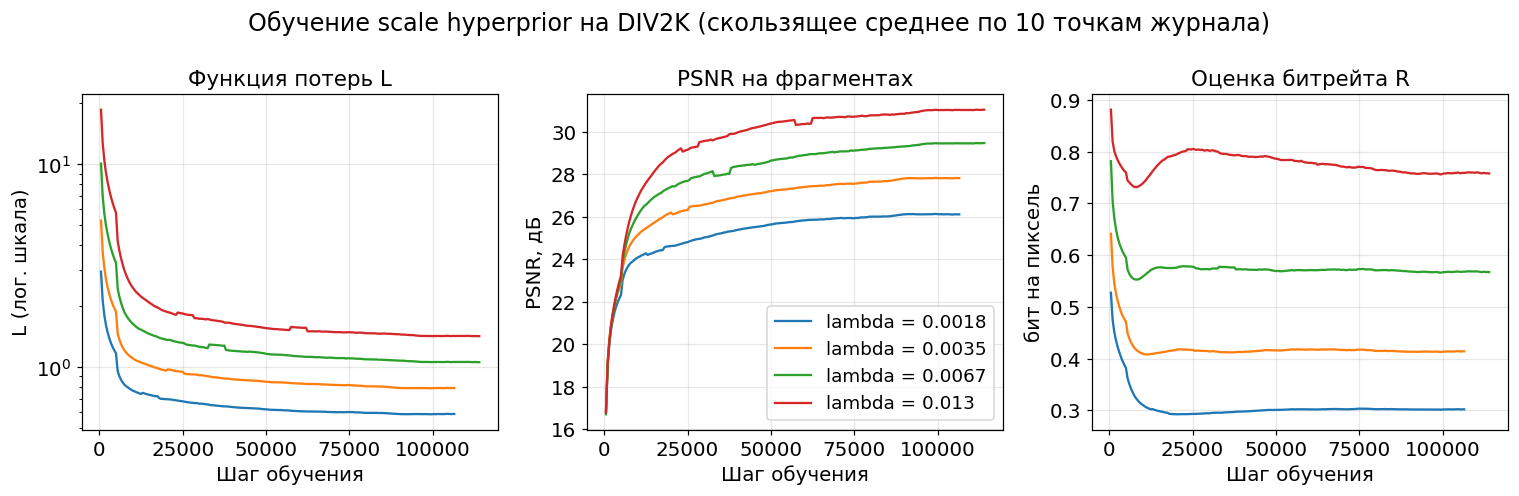

In [15]:
# Кривые обучения: функция потерь, PSNR и битрейт на обучающих фрагментах
logs = pd.concat([pd.read_csv(p) for p in sorted(KAGGLE_DIR.glob("night-*/train_log.csv"))], ignore_index=True)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
for lmbda, part in logs.groupby("lambda"):
    # Скользящее среднее по 10 точкам журнала; сырые значения шумят из-за случайных фрагментов
    smooth = part.set_index("step")[["loss", "psnr", "bpp"]].rolling(10, min_periods=1).mean()
    axes[0].plot(smooth.index, smooth["loss"], label=f"lambda = {lmbda}")
    axes[1].plot(smooth.index, smooth["psnr"], label=f"lambda = {lmbda}")
    axes[2].plot(smooth.index, smooth["bpp"], label=f"lambda = {lmbda}")
axes[0].set_yscale("log")
for axis, title, ylabel in zip(axes, ["Функция потерь L", "PSNR на фрагментах", "Оценка битрейта R"],
                               ["L (лог. шкала)", "PSNR, дБ", "бит на пиксель"]):
    axis.set_title(title)
    axis.set_xlabel("Шаг обучения")
    axis.set_ylabel(ylabel)
    axis.grid(alpha=0.3)
axes[1].legend(fontsize=12)
fig.suptitle("Обучение scale hyperprior на DIV2K (скользящее среднее по 10 точкам журнала)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "training-curves.png", dpi=150, bbox_inches="tight")
plt.show()

**Результат:** За 9 часов каждая модель сделала 106 516 (λ 0,0018 и 0,0035) или 114 326 шагов (λ 0,0067 и 0,013), 3,3-3,5 шага в секунду на одной Tesla T4. Сеть занимает 2,0 ГБ памяти GPU, поэтому две модели обучались параллельно на двух картах одной сессии. Основное улучшение - первые 10-20 тыс. шагов; затем PSNR медленно растет, а оценка битрейта почти постоянна. После снижения шага на 80% времени кривые выходят на плато: для этого рецепта 9 часов близки к пределу. Битрейт на графике - оценка при обучении (шум вместо округления, другие изображения), поэтому он выше реального на Kodak и напрямую с ним не сравнивается.

## Оценка на Kodak

Каждое изображение проходит через настоящий энтропийный кодер: `compress` дает байты, `decompress` восстанавливает изображение только из них. Восстановленные пиксели округляются до 8 бит, как у JPEG/WebP и PULSE. Оцениваются наши 4 модели и официальные веса CompressAI той же архитектуры (качества 1-4).

In [16]:
# Метрики качества: тот же набор и те же реализации, что для всех остальных кодеков
import pyiqa
from torchmetrics.image import LearnedPerceptualImagePatchSimilarity

metrics = {
    "psnr": pyiqa.create_metric("psnr").to(DEVICE).eval(),
    "ms_ssim": pyiqa.create_metric("ms_ssim").to(DEVICE).eval(),
    "dists": pyiqa.create_metric("dists").to(DEVICE).eval(),
    "clipiqa": pyiqa.create_metric("clipiqa").to(DEVICE).eval(),
    "musiq": pyiqa.create_metric("musiq").to(DEVICE).eval(),
    "lpips": LearnedPerceptualImagePatchSimilarity(net_type="alex", normalize=True).to(DEVICE).eval(),
}
METRIC_NAMES = ["psnr", "ms_ssim", "lpips", "dists", "clipiqa", "musiq"]


@torch.no_grad()
def score(reconstruction, original):
    """Все метрики для пары изображений RGB в [0, 1], форма [1, 3, H, W]."""
    return {name: float(metrics[name](reconstruction, original).item()) for name in METRIC_NAMES}

Loading pretrained model DISTS from /home/bigfly/projects/Deep-Image-Compression-ditic/src/models/cache/torch/hub/pyiqa/DISTS_weights-f5e65c96.pth


Loading pretrained model MUSIQ from /home/bigfly/projects/Deep-Image-Compression-ditic/src/models/cache/torch/hub/pyiqa/musiq_koniq_ckpt-e95806b9.pth


In [17]:
# Загрузка моделей: наши веса с Kaggle и официальные веса CompressAI
from compressai.zoo import bmshj2018_hyperprior

ZOO_LAMBDAS = {1: 0.0018, 2: 0.0035, 3: 0.0067, 4: 0.0130}  # качество CompressAI -> lambda обучения

hyperprior_models = []
for checkpoint in sorted(KAGGLE_DIR.glob("night-*/hyperprior_lmbda*.pth")):
    lmbda = float(checkpoint.stem.replace("hyperprior_lmbda", ""))
    # from_state_dict сам берет размеры N, M из весов и готовит буферы энтропийного кодера
    net = ScaleHyperprior.from_state_dict(torch.load(checkpoint, map_location="cpu", weights_only=True))
    hyperprior_models.append(("Наш кодек", lmbda, net))
# Проверка: ровно одна наша модель на каждое lambda, иначе результаты двух моделей смешались бы
our_lambdas = [lmbda for codec, lmbda, _ in hyperprior_models if codec == "Наш кодек"]
assert sorted(our_lambdas) == sorted(set(our_lambdas)), f"повтор lambda: {our_lambdas}"
for quality, lmbda in ZOO_LAMBDAS.items():
    net = bmshj2018_hyperprior(quality=quality, metric="mse", pretrained=True)
    hyperprior_models.append(("CompressAI (эталон)", lmbda, net))

for _, _, net in hyperprior_models:
    net.to(DEVICE).eval()
    net.update(force=True)  # целочисленные таблицы распределений для арифметического кодера
print("Моделей для оценки:", len(hyperprior_models))

Моделей для оценки: 8


In [18]:
# Кодирование и декодирование Kodak реальным битовым потоком
SHAPE_HEADER_BYTES = 4  # высота и ширина латента, которые файл тоже должен хранить


def synchronize():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize(DEVICE)


@torch.no_grad()
def code_image(net, x):
    """Сжатие в байты и восстановление; возвращает 8-битную реконструкцию, байты и время."""
    height, width = x.shape[-2:]
    # Сеть уменьшает размер в 64 раза, поэтому изображение дополняется до кратного 64
    x_padded = F.pad(x, (0, (-width) % 64, 0, (-height) % 64), mode="replicate")
    synchronize(); t0 = time.perf_counter()
    encoded = net.compress(x_padded)
    synchronize(); encode_ms = (time.perf_counter() - t0) * 1000
    n_bytes = sum(len(s[0]) for s in encoded["strings"]) + SHAPE_HEADER_BYTES
    t0 = time.perf_counter()
    x_hat = net.decompress(encoded["strings"], encoded["shape"])["x_hat"]
    synchronize(); decode_ms = (time.perf_counter() - t0) * 1000
    x_hat = (x_hat[..., :height, :width].clamp(0, 1) * 255).round() / 255
    return x_hat, n_bytes, encode_ms, decode_ms


def to_tensor(image):
    return torch.from_numpy(np.array(image.convert("RGB"))).permute(2, 0, 1)[None].float().div(255)


rows = []
torch.cuda.reset_peak_memory_stats() if DEVICE.type == "cuda" else None
for codec, lmbda, net in hyperprior_models:
    for path in kodak_paths:
        original = to_tensor(Image.open(path)).to(DEVICE)
        reconstruction, n_bytes, encode_ms, decode_ms = code_image(net, original)
        rows.append({"codec": codec, "lmbda": lmbda, "image": path.stem,
                     "bpp": n_bytes * 8 / (original.shape[2] * original.shape[3]), "bytes": n_bytes,
                     "encode_ms": encode_ms, "decode_ms": decode_ms, **score(reconstruction, original)})
hyperprior_rows = pd.DataFrame(rows)
hyperprior_summary = (hyperprior_rows.groupby(["codec", "lmbda"])[["bpp", *METRIC_NAMES, "encode_ms", "decode_ms"]]
                      .mean().reset_index())
# В файлах - те же имена кодеков, что пишет src/scripts/run_hyperprior.py (их читает make_plots.py)
CODEC_IDS = {"Наш кодек": "hyperprior-ours", "CompressAI (эталон)": "hyperprior-zoo"}
for frame, file_name in ((hyperprior_rows, "hyperprior_kodak.csv"), (hyperprior_summary, "hyperprior_kodak_summary.csv")):
    frame.assign(codec=frame["codec"].map(CODEC_IDS)).to_csv(METRICS_DIR / file_name, index=False)
display(hyperprior_summary[["codec", "lmbda", "bpp", "psnr", "ms_ssim", "lpips", "dists"]])

,codec,lmbda,bpp,psnr,ms_ssim,lpips,dists
0,CompressAI (эталон),0.0018,0.1314,27.5780,0.9271,0.3761,0.2284
1,CompressAI (эталон),0.0035,0.2090,29.1919,0.9502,0.2989,0.1917
2,CompressAI (эталон),0.0067,0.3199,30.9637,0.9674,0.2284,0.1587
3,CompressAI (эталон),0.0130,0.4785,32.8276,0.9797,0.1640,0.1283
4,Наш кодек,0.0018,0.1478,27.2568,0.9282,0.3755,0.2167
5,Наш кодек,0.0035,0.2430,29.0635,0.9513,0.2881,0.1788
6,Наш кодек,0.0067,0.3825,30.8113,0.9698,0.2112,0.1447
7,Наш кодек,0.0130,0.5768,32.8194,0.9819,0.1439,0.1102


In [19]:
# Насколько наше короткое обучение уступает полному: разница PSNR при том же lambda
ours = hyperprior_summary[hyperprior_summary["codec"] == "Наш кодек"].set_index("lmbda")
zoo = hyperprior_summary[hyperprior_summary["codec"] == "CompressAI (эталон)"].set_index("lmbda")
gap = pd.DataFrame({
    "bpp (наш)": ours["bpp"], "PSNR (наш), дБ": ours["psnr"],
    "bpp (CompressAI)": zoo["bpp"], "PSNR (CompressAI), дБ": zoo["psnr"],
})
# PSNR CompressAI на битрейте нашей модели (линейная интерполяция по кривой CompressAI)
# Вне измеренного диапазона CompressAI интерполяция не определена - там NaN
inside = gap["bpp (наш)"].between(zoo["bpp"].min(), zoo["bpp"].max())
gap["PSNR CompressAI при том же bpp, дБ"] = np.where(
    inside, np.interp(gap["bpp (наш)"], zoo["bpp"], zoo["psnr"]), np.nan)
gap["Отставание, дБ"] = gap["PSNR CompressAI при том же bpp, дБ"] - gap["PSNR (наш), дБ"]
gap.reset_index().to_csv(METRICS_DIR / "project-ours-vs-zoo.csv", index=False)
display(gap)

,bpp (наш),"PSNR (наш), дБ",bpp (CompressAI),"PSNR (CompressAI), дБ","PSNR CompressAI при том же bpp, дБ","Отставание, дБ"
lmbda,,,,,,
0.0018,0.1478,27.2568,0.1314,27.5780,27.9205,0.6636
0.0035,0.2430,29.0635,0.2090,29.1919,29.7348,0.6713
0.0067,0.3825,30.8113,0.3199,30.9637,31.6989,0.8876
0.0130,0.5768,32.8194,0.4785,32.8276,NaN,NaN


**Результат:** При том же λ наши модели тратят на 12-21% больше бит при близком PSNR. При равном битрейте отставание от официальных весов - 0,66-0,89 дБ; для λ 0,013 сравнить нельзя: наш битрейт 0,577 выше наибольшего у CompressAI (0,479). Сеть одна и та же, поэтому разница - от обучения: у CompressAI другие данные и расписание шага, у нас 9 часов на T4. По LPIPS и DISTS при том же lambda наши модели даже немного лучше, но только за счет большего битрейта.

## Сравнение кодеков

Результаты остальных кодеков получены на тех же 24 изображениях Kodak и посчитаны тем же кодом метрик (проверено повторным расчетом строки JPEG q50: совпадение до 0,0003). Для JPEG и WebP перебиралась сетка "масштаб x качество" (при очень низком битрейте изображение уменьшается перед сжатием), и на графиках показана лучшая достигнутая точка для каждого битрейта. У PULSE и hyperprior показаны все измеренные точки. Одно отличие в подсчете: метрики DiT-IC посчитаны по реконструкции до округления пикселей до 8 бит, у остальных кодеков - после.

In [20]:
# Сводная таблица всех кодеков: одна строка - одна рабочая точка (средние по 24 изображениям)
def pareto(frame, metric, higher_is_better):
    """Огибающая лучших значений по битрейту (для сетки JPEG/WebP)."""
    frame = frame.sort_values("bpp")
    best, keep = None, []
    for index, value in frame[metric].items():
        if best is None or (value > best if higher_is_better else value < best):
            best = value
            keep.append(index)
    return frame.loc[keep]


baselines = pd.read_csv(METRICS_DIR / "baselines_kodak_summary.csv")
baselines["codec"] = baselines["codec"].map({"jpeg": "JPEG", "webp": "WebP"})
baselines["setting"] = "масштаб " + baselines["scale"].astype(str) + ", качество " + baselines["quality"].astype(str)

pulse = pd.read_csv(METRICS_DIR / "pulse_kodak_summary.csv")
pulse_names = {"pulse-s-mse": "PULSE-S (точность)", "pulse-mse": "PULSE (точность)",
               "pulse-perceptual": "PULSE (восприятие)", "pulse-l-perceptual": "PULSE-L (восприятие)"}
pulse["codec"] = pulse["codec"].map(pulse_names)
pulse["setting"] = "QP " + pulse["qp"].astype(str)

hyper = hyperprior_summary.copy()
hyper["setting"] = "lambda " + hyper["lmbda"].astype(str)

dit_rows = []
for path in sorted(METRICS_DIR.glob("dit_ic_q*_summary.json")):
    summary = json.loads(path.read_text())
    dit_rows.append({"codec": "DiT-IC", "setting": summary["tag"].replace("dit_ic_", ""),
                     **{key[4:]: summary[key] for key in summary if key.startswith("avg_")}})
dit = pd.DataFrame(dit_rows)

columns = ["codec", "setting", "bpp", *METRIC_NAMES, "encode_ms", "decode_ms"]
all_points = pd.concat([baselines[columns], hyper[columns], pulse[columns], dit[columns]], ignore_index=True)
print("Рабочих точек:", all_points.groupby("codec").size().to_dict())

Рабочих точек: {'CompressAI (эталон)': 4, 'DiT-IC': 1, 'JPEG': 40, 'PULSE (восприятие)': 8, 'PULSE (точность)': 8, 'PULSE-L (восприятие)': 8, 'PULSE-S (точность)': 8, 'WebP': 40, 'Наш кодек': 4}


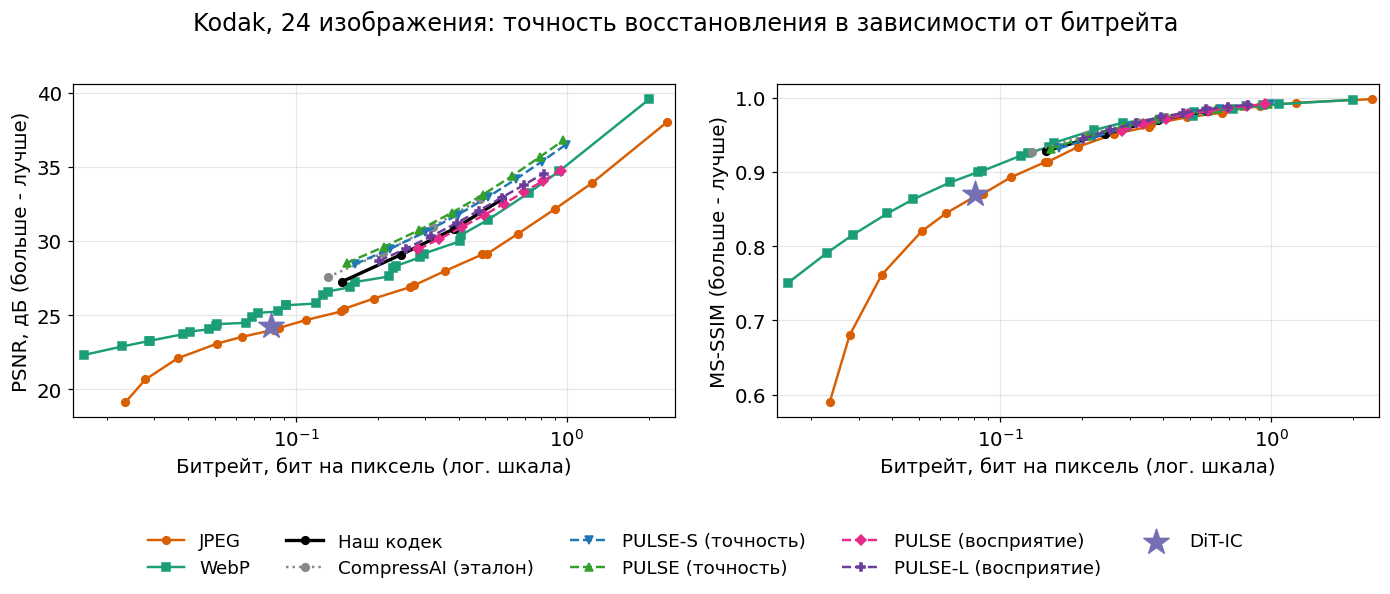

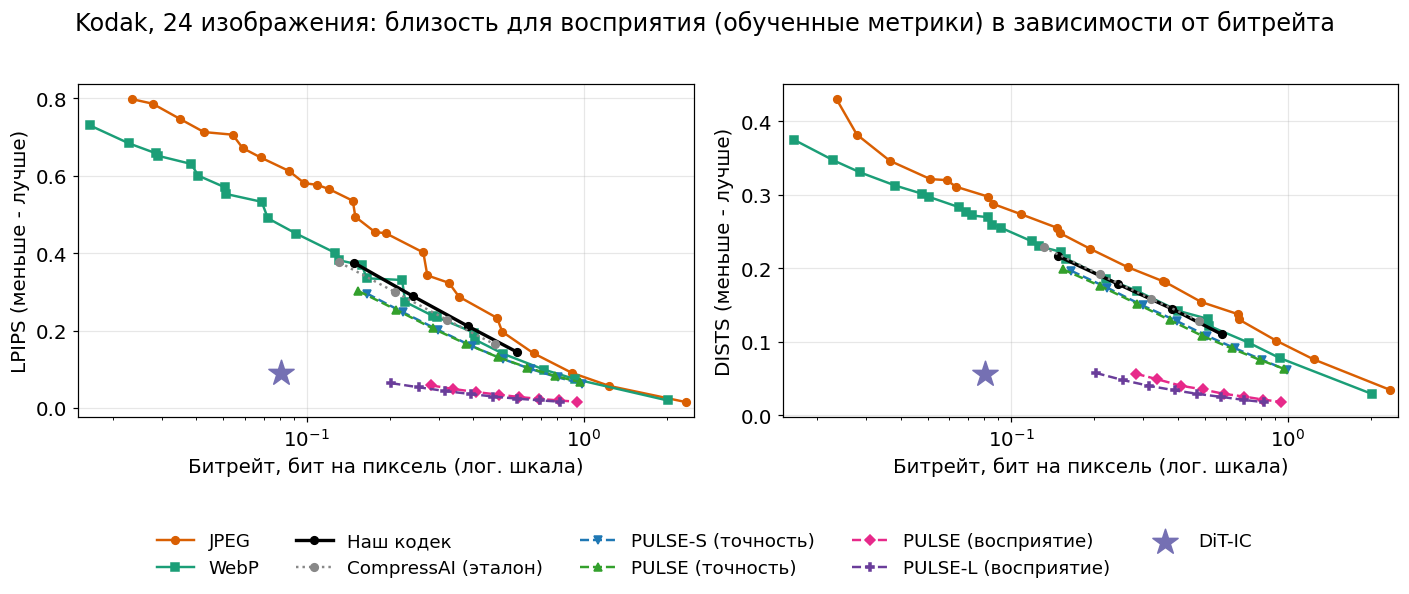

In [21]:
# Кривые "битрейт - качество" для четырех метрик
STYLE = {
    "JPEG": dict(color="#d95f02", marker="o"), "WebP": dict(color="#1b9e77", marker="s"),
    "Наш кодек": dict(color="black", marker="o", linewidth=2.2),
    "CompressAI (эталон)": dict(color="#888888", marker="o", linestyle=":"),
    "PULSE-S (точность)": dict(color="#1f78b4", marker="v", linestyle="--"),
    "PULSE (точность)": dict(color="#33a02c", marker="^", linestyle="--"),
    "PULSE (восприятие)": dict(color="#e7298a", marker="D", linestyle="--"),
    "PULSE-L (восприятие)": dict(color="#6a3d9a", marker="P", linestyle="--"),
}
PLOTS = [("psnr", "PSNR, дБ (больше - лучше)", True), ("ms_ssim", "MS-SSIM (больше - лучше)", True),
         ("lpips", "LPIPS (меньше - лучше)", False), ("dists", "DISTS (меньше - лучше)", False)]

# Две пары метрик: точность восстановления пикселей и близость для восприятия
FIGURES = [("rd-fidelity.png", "Точность восстановления", PLOTS[:2]),
           ("rd-perceptual.png", "Близость для восприятия (обученные метрики)", PLOTS[2:])]
for file_name, title, plots in FIGURES:
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.4))
    for axis, (metric, label, higher) in zip(axes, plots):
        for codec, style in STYLE.items():
            part = all_points[all_points["codec"] == codec]
            if codec in ("JPEG", "WebP"):
                part = pareto(part, metric, higher)
            part = part.sort_values("bpp")
            axis.plot(part["bpp"], part[metric], markersize=5, label=codec, **{"linewidth": 1.6, **style})
        axis.scatter(dit["bpp"], dit[metric], marker="*", s=300, color="#7570b3", zorder=5, label="DiT-IC")
        axis.set_xscale("log")
        axis.set_xlim(0.015, 2.5)
        axis.set_xlabel("Битрейт, бит на пиксель (лог. шкала)")
        axis.set_ylabel(label)
        axis.grid(alpha=0.3)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=5, frameon=False, fontsize=12)
    fig.suptitle(f"Kodak, 24 изображения: {title.lower()} в зависимости от битрейта")
    fig.tight_layout(rect=(0, 0.16, 1, 0.97))
    fig.savefig(FIGURES_DIR / file_name, dpi=150, bbox_inches="tight")
    plt.show()

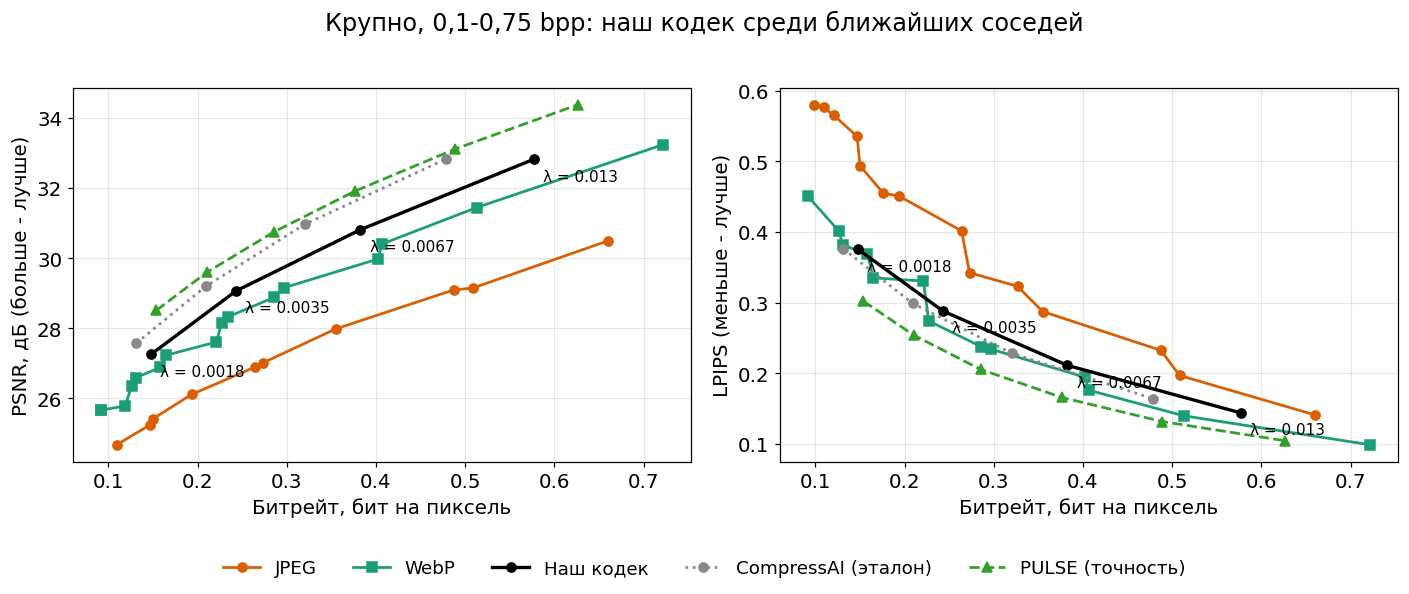

In [22]:
# Крупно: наш кодек рядом с эталоном CompressAI, WebP, JPEG и PULSE (точность), 0,1-0,75 bpp, линейная шкала
ZOOM = ["JPEG", "WebP", "Наш кодек", "CompressAI (эталон)", "PULSE (точность)"]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.4))
for axis, (metric, label, higher) in zip(axes, [PLOTS[0], PLOTS[2]]):
    for codec in ZOOM:
        part = all_points[all_points["codec"] == codec]
        if codec in ("JPEG", "WebP"):
            part = pareto(part, metric, higher)
        part = part[part["bpp"].between(0.09, 0.75)].sort_values("bpp")
        axis.plot(part["bpp"], part[metric], markersize=6, label=codec, **{"linewidth": 1.8, **STYLE[codec]})
    # Подписи lambda у точек нашего кодека
    for _, row in all_points[all_points["codec"] == "Наш кодек"].iterrows():
        axis.annotate("λ = " + row["setting"].split()[-1], (row["bpp"], row[metric]),
                      textcoords="offset points", xytext=(6, -14), fontsize=10)
    axis.set_xlabel("Битрейт, бит на пиксель")
    axis.set_ylabel(label)
    axis.grid(alpha=0.3)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=5, frameon=False, fontsize=12)
fig.suptitle("Крупно, 0,1-0,75 bpp: наш кодек среди ближайших соседей")
fig.tight_layout(rect=(0, 0.09, 1, 0.97))
fig.savefig(FIGURES_DIR / "rd-zoom.png", dpi=150, bbox_inches="tight")
plt.show()

**Результат:** При равном битрейте наш кодек лучше JPEG на 1,9-2,6 дБ и WebP на 0,5-1,0 дБ (0,15-0,4 bpp), но уступает эталону CompressAI на 0,7-0,9 дБ и PULSE (точность) примерно на 1,2 дБ. По MS-SSIM все кодеки, кроме JPEG, почти совпадают. По LPIPS и DISTS наш кодек на уровне WebP (LPIPS 0,328 против 0,332 при 0,2 bpp). PULSE на восприятие дает LPIPS 0,035-0,046 при 0,3-0,4 bpp - в 3,5-6 раз ниже кодеков на точность; DiT-IC при 0,08 bpp (LPIPS 0,091) лучше любого кодека на точность даже при 0,5 bpp.

In [23]:
# Таблица при сопоставимом битрейте: для каждого кодека - измеренная точка, ближайшая к цели
def nearest(frame, target):
    return frame.loc[(frame["bpp"] - target).abs().idxmin()]


tables = {}
for target in (0.1, 0.2, 0.4):
    picked = []
    for codec in all_points["codec"].unique():
        part = all_points[all_points["codec"] == codec]
        # У JPEG/WebP много настроек; настройка, которую другая превосходит при меньшем битрейте,
        # не берется (выбор только из огибающей по PSNR)
        if codec in ("JPEG", "WebP"):
            part = pareto(part, "psnr", True)
        picked.append(nearest(part, target))
    table = pd.DataFrame(picked)[["codec", "setting", "bpp", "psnr", "ms_ssim", "lpips", "dists"]]
    # Точки дальше 30% от цели не считаются сопоставимыми
    table = table[(table["bpp"] - target).abs() <= 0.3 * target].sort_values("psnr", ascending=False)
    table.columns = ["Кодек", "Настройка", "bpp", "PSNR, дБ", "MS-SSIM", "LPIPS", "DISTS"]
    tables[target] = table.reset_index(drop=True)
    print(f"\nЦелевой битрейт около {target} bpp (допуск 30%):")
    display(tables[target])
# Все три таблицы в один файл для презентации
pd.concat([t.assign(**{"Цель, bpp": target}) for target, t in tables.items()]).to_csv(
    METRICS_DIR / "project-matched.csv", index=False)


Целевой битрейт около 0.1 bpp (допуск 30%):


,Кодек,Настройка,bpp,"PSNR, дБ",MS-SSIM,LPIPS,DISTS
0,WebP,"масштаб 0.7, качество 1",0.0919,25.6643,0.8844,0.4516,0.2640
1,JPEG,"масштаб 0.35, качество 30",0.1092,24.6768,0.8925,0.5764,0.2734
2,DiT-IC,q3,0.0805,24.2451,0.8708,0.0911,0.0554



Целевой битрейт около 0.2 bpp (допуск 30%):


,Кодек,Настройка,bpp,"PSNR, дБ",MS-SSIM,LPIPS,DISTS
0,PULSE (точность),QP 1,0.2103,29.5947,0.9477,0.2539,0.1758
1,PULSE-S (точность),QP 1,0.2222,29.4688,0.9472,0.2476,0.1737
2,CompressAI (эталон),lambda 0.0035,0.2090,29.1919,0.9502,0.2989,0.1917
3,Наш кодек,lambda 0.0035,0.2430,29.0635,0.9513,0.2881,0.1788
4,PULSE-L (восприятие),QP 0,0.2022,28.6492,0.9447,0.0640,0.0576
5,WebP,"масштаб 0.5, качество 50",0.2211,27.6093,0.9563,0.3306,0.1860
6,JPEG,"масштаб 0.5, качество 30",0.1933,26.1137,0.9336,0.4512,0.2265



Целевой битрейт около 0.4 bpp (допуск 30%):


,Кодек,Настройка,bpp,"PSNR, дБ",MS-SSIM,LPIPS,DISTS
0,CompressAI (эталон),lambda 0.013,0.4785,32.8276,0.9797,0.1640,0.1283
1,PULSE (точность),QP 3,0.3762,31.9099,0.9709,0.1657,0.1292
2,PULSE-S (точность),QP 3,0.3967,31.7798,0.9708,0.1591,0.1283
3,PULSE-L (восприятие),QP 3,0.3924,31.2210,0.9738,0.0358,0.0337
4,PULSE (восприятие),QP 2,0.4097,30.9361,0.9714,0.0410,0.0403
5,Наш кодек,lambda 0.0067,0.3825,30.8113,0.9698,0.2112,0.1447
6,WebP,"масштаб 0.7, качество 50",0.4019,29.9729,0.9728,0.1944,0.1421
7,JPEG,"масштаб 0.7, качество 30",0.3548,27.9813,0.9609,0.2874,0.1823


**Результат:** в таблицах - измеренные точки, ближайшие к цели, поэтому битрейты кодеков немного различаются; сравнение при строго равном битрейте дают кривые выше. До 0,1 bpp из обучаемых кодеков доходит только DiT-IC: минимум нашего кодека 0,148, CompressAI 0,131, PULSE 0,154 bpp. По PSNR DiT-IC уступает WebP (24,25 против 25,66 дБ), но его LPIPS 0,091 в 5 раз ниже - он дорисовывает правдоподобные детали. При 0,2 bpp: лучший PSNR у PULSE (точность), 29,59 дБ. Битрейты в таблице немного различаются: наш кодек дает 29,06 дБ при 0,243 bpp, а при равных 0,2 bpp он выше WebP на 0,8 дБ и JPEG на 2,1 дБ. PULSE-L (восприятие) теряет около 1 дБ PSNR, но его LPIPS 0,064 в 4-7 раз ниже остальных. При 0,4 bpp: строка CompressAI получена при 0,479 bpp - на 20% больше бит, чем у соседей; при равных 0,4 bpp впереди PULSE (точность): 32,16 против 31,90 дБ. При равных 0,4 bpp наш кодек (31,0 дБ) лучше WebP на 1,0 дБ и JPEG на 2,6 дБ.

### Визуальное сравнение

Один и тот же фрагмент изображения Kodak при сопоставимом битрейте, в исходном масштабе пикселей. Для каждого кодека берется та настройка, при которой битрейт именно этого изображения ближе всего к цели (у разных изображений при одной настройке битрейт разный). Под каждым фрагментом - битрейт всего изображения.

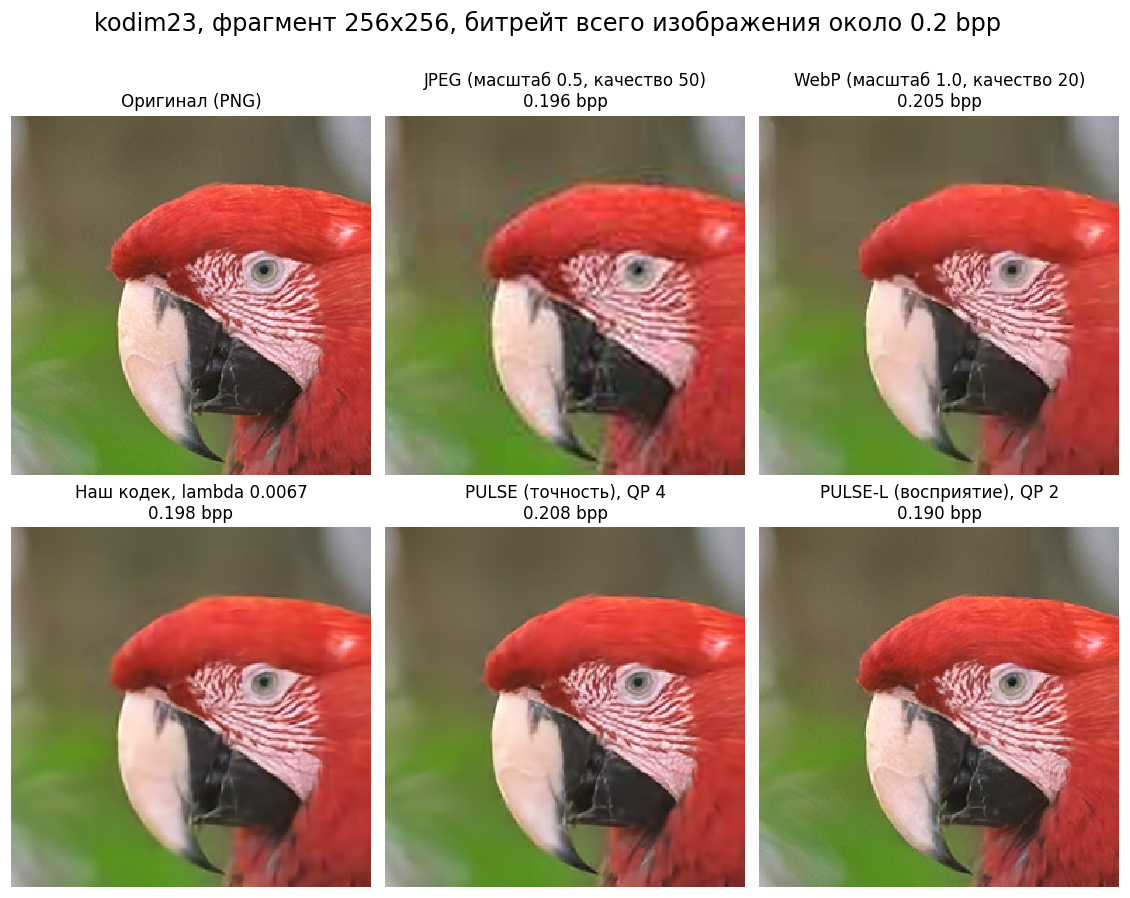

In [24]:
# Фрагмент kodim23 (попугаи: мелкие перья и гладкий фон) при битрейте около 0.2 bpp
import io

IMAGE_NAME, TARGET_BPP = "kodim23", 0.2
CROP = (330, 60, 330 + 256, 60 + 256)  # left, top, right, bottom
original_image = Image.open(KODAK_DIR / f"{IMAGE_NAME}.png").convert("RGB")


NUM_PIXELS = original_image.size[0] * original_image.size[1]
# У каждого изображения свой битрейт при одной настройке, поэтому настройка
# выбирается по битрейту именно этого изображения, а не по среднему по Kodak.


def classic_codec(image, codec):
    """JPEG/WebP: перебор всей сетки "масштаб x качество" на этом изображении, ближайший к цели битрейт."""
    best = None
    for _, row in baselines[baselines["codec"] == codec].iterrows():
        small = image if row["scale"] == 1.0 else image.resize(
            (round(image.size[0] * row["scale"]), round(image.size[1] * row["scale"])), Image.Resampling.LANCZOS)
        buffer = io.BytesIO()
        small.save(buffer, format="JPEG" if codec == "JPEG" else "WEBP", quality=int(row["quality"]))
        bpp = len(buffer.getvalue()) * 8 / NUM_PIXELS
        if best is None or abs(bpp - TARGET_BPP) < abs(best[1] - TARGET_BPP):
            restored = Image.open(io.BytesIO(buffer.getvalue())).convert("RGB").resize(image.size, Image.Resampling.LANCZOS)
            best = (restored, bpp, row["setting"])
    return best


panels = [("Оригинал (PNG)", original_image, None)]
for codec in ("JPEG", "WebP"):
    restored, bpp, setting = classic_codec(original_image, codec)
    panels.append((f"{codec} ({setting})", restored, bpp))

# Наш hyperprior: модель, у которой битрейт kodim23 ближе всего к цели
ours_image = hyperprior_rows[(hyperprior_rows["codec"] == "Наш кодек") & (hyperprior_rows["image"] == IMAGE_NAME)]
best_lmbda = ours_image.loc[(ours_image["bpp"] - TARGET_BPP).abs().idxmin(), "lmbda"]
net = next(n for c, l, n in hyperprior_models if c == "Наш кодек" and l == best_lmbda)
restored_tensor, n_bytes, _, _ = code_image(net, to_tensor(original_image).to(DEVICE))
restored = Image.fromarray((restored_tensor[0].permute(1, 2, 0).cpu().numpy() * 255).round().astype(np.uint8))
panels.append((f"Наш кодек, lambda {best_lmbda}", restored, n_bytes * 8 / NUM_PIXELS))

# PULSE: сохраненная реконструкция того QP, у которого битрейт kodim23 ближе всего к цели
pulse_rows = pd.read_csv(METRICS_DIR / "pulse_kodak.csv")
for model, name in (("pulse-mse", "PULSE (точность)"), ("pulse-l-perceptual", "PULSE-L (восприятие)")):
    rows_image = pulse_rows[(pulse_rows["codec"] == model) & (pulse_rows["image"] == IMAGE_NAME)]
    picked = rows_image.loc[(rows_image["bpp"] - TARGET_BPP).abs().idxmin()]
    qp = int(picked["qp"])
    restored = Image.open(PULSE_DIR / model / "rec" / f"qp{qp}" / f"{IMAGE_NAME}.png").convert("RGB")
    panels.append((f"{name}, QP {qp}", restored, float(picked["bpp"])))

fig, axes = plt.subplots(2, 3, figsize=(13, 9.2), gridspec_kw={"hspace": 0.12, "wspace": 0.04})
for axis, (title, image, bpp) in zip(axes.ravel(), panels):
    axis.imshow(image.crop(CROP), interpolation="nearest")
    axis.set_title(title if bpp is None else f"{title}\n{bpp:.3f} bpp", fontsize=11)
    axis.axis("off")
fig.suptitle(f"{IMAGE_NAME}, фрагмент 256x256, битрейт всего изображения около {TARGET_BPP} bpp")
fig.savefig(FIGURES_DIR / "visual-crops.png", dpi=150, bbox_inches="tight")
plt.show()

**Результат:** У JPEG видны блоки и ореолы, у WebP сглажены полосы перьев. Наш кодек и PULSE (точность) сохраняют полосы и контуры, слегка размывая фон. PULSE-L (восприятие) возвращает зернистую текстуру и ближе всех к оригиналу на глаз, хотя по PSNR ниже. DiT-IC здесь нет: при 0,2 bpp он не работает. Для kodim23 битрейту 0,2 bpp соответствует наша модель с lambda 0,0067: это изображение проще среднего по Kodak.

In [25]:
# Сложность моделей: число весов, время кодирования и декодирования одного изображения Kodak
complexity = pd.DataFrame([
    {"Кодек": "JPEG / WebP", "Весов, млн": 0.0, "Кодирование, мс": baselines["encode_ms"].median(),
     "Декодирование, мс": baselines["decode_ms"].median(), "Где измерено": "CPU (Pillow), настольный ПК"},
    {"Кодек": "Наш кодек", "Весов, млн": sum(p.numel() for p in model_demo.parameters()) / 1e6,
     "Кодирование, мс": hyperprior_rows[hyperprior_rows["codec"] == "Наш кодек"]["encode_ms"].median(),
     "Декодирование, мс": hyperprior_rows[hyperprior_rows["codec"] == "Наш кодек"]["decode_ms"].median(),
     "Где измерено": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"},
])
# Число весов PULSE прочитано из файлов model.pt (вместе с буферами), время - из run_pulse.py (RTX 4070 Laptop)
pulse_weights = {"PULSE-S (точность)": 12.67, "PULSE (точность)": 14.72, "PULSE (восприятие)": 14.72, "PULSE-L (восприятие)": 19.29}
pulse_times = pd.read_csv(METRICS_DIR / "pulse_kodak.csv").assign(codec=lambda d: d["codec"].map(pulse_names))
for name, weights in pulse_weights.items():
    part = pulse_times[pulse_times["codec"] == name]
    complexity.loc[len(complexity)] = {"Кодек": name, "Весов, млн": weights,
                                       "Кодирование, мс": part["encode_ms"].median(),
                                       "Декодирование, мс": part["decode_ms"].median(),
                                       "Где измерено": "NVIDIA GeForce RTX 4070 Laptop GPU"}
dit_summary = json.loads((METRICS_DIR / "dit_ic_q3_summary.json").read_text())
complexity.loc[len(complexity)] = {"Кодек": "DiT-IC", "Весов, млн": dit_summary["parameters_b"] * 1000,
                                   "Кодирование, мс": dit_summary["median_encode_ms"],
                                   "Декодирование, мс": dit_summary["median_decode_ms"],
                                   "Где измерено": dit_summary["gpu"] + ", настольный ПК"}
complexity.to_csv(METRICS_DIR / "project-complexity.csv", index=False)
display(complexity)

,Кодек,"Весов, млн","Кодирование, мс","Декодирование, мс",Где измерено
0,JPEG / WebP,0.0000,2.3214,7.1068,"CPU (Pillow), настольный ПК"
1,Наш кодек,5.0758,30.8069,40.3121,NVIDIA GeForce RTX 4070 Laptop GPU
2,PULSE-S (точность),12.6700,86.3193,33.8464,NVIDIA GeForce RTX 4070 Laptop GPU
3,PULSE (точность),14.7200,68.4664,33.6144,NVIDIA GeForce RTX 4070 Laptop GPU
4,PULSE (восприятие),14.7200,82.7454,43.4543,NVIDIA GeForce RTX 4070 Laptop GPU
5,PULSE-L (восприятие),19.2900,101.8479,80.5913,NVIDIA GeForce RTX 4070 Laptop GPU
6,DiT-IC,1069.4112,277.6011,391.8151,"NVIDIA GeForce RTX 5060 Ti, настольный ПК"


**Результат:** Наш кодек - самый легкий из обучаемых: 5,1 млн весов, 31 мс на кодирование и 40 мс на декодирование изображения Kodak на ноутбучной RTX 4070. PULSE в 2,5-4 раза больше, кодирует в 2,2-3,3 раза медленнее, декодирует так же или до 2 раз медленнее; DiT-IC больше в 200 раз и медленнее примерно в 9-10 раз. Компьютеры разные, поэтому сравнение - по порядку величины.

## Вывод

1. **Изученные методы.** Изучены три направления обучаемого сжатия и устройство нейросетевого кодека с подсказкой о масштабе (scale hyperprior). Для сравнения выбраны кодеки трех типов: классические JPEG и WebP, обучаемые на точность (наш, PULSE) и на восприятие (PULSE), генеративный DiT-IC; качество оценено шестью метриками по реальному размеру файла.

2. **Собственный кодек.** Собственный кодек (5,08 млн весов) обучен с нуля на DIV2K: 4 модели λ 0,0018-0,013, по 9 часов на Tesla T4 (106-114 тыс. шагов). На Kodak он дает 0,148-0,577 bpp при PSNR 27,26-32,82 дБ; до официальных весов той же сети не хватает 0,66-0,89 дБ при равном битрейте.

3. **Сравнение.** При равном битрейте наш кодек лучше JPEG на 1,9-2,6 дБ PSNR и WebP на 0,5-1,0 дБ, по MS-SSIM, LPIPS и DISTS он на уровне WebP. Лучший по PSNR - PULSE на точность, по восприятию - PULSE на восприятие (LPIPS 0,035-0,046) и DiT-IC (LPIPS 0,091 при 0,08 bpp). Цель достигнута частично: кодек обходит традиционные, но для высокого визуального качества при низком битрейте нужна функция потерь с учетом восприятия - следующий шаг.

4. **Почему так.** Кодеки на MSE усредняют детали, которые нельзя передать, поэтому выигрывают по PSNR и проигрывают по LPIPS; кодеки на восприятие и генеративные дорисовывают текстуру. Обучаемые нелинейные преобразования и энтропийная модель с гиперприором сжимают лучше фиксированного DCT. Разница с официальными весами той же сети объясняется рецептом обучения, а не архитектурой.